In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", None)
df = pd.read_csv("ecommerce_customer_behavior_dataset.csv")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
display(df.head())

Dataset shape: (5000, 18)

Column names:
['Order_ID', 'Customer_ID', 'Date', 'Age', 'Gender', 'City', 'Product_Category', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount', 'Payment_Method', 'Device_Type', 'Session_Duration_Minutes', 'Pages_Viewed', 'Is_Returning_Customer', 'Delivery_Time_Days', 'Customer_Rating']


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,Mobile,8,10,False,1,4
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,Cash on Delivery,Desktop,21,10,True,7,4


In [32]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("\nDate column data type:", df["Date"].dtype)
print("Invalid dates:", df["Date"].isna().sum())
print("Earliest transaction:", df["Date"].min())
print("Latest transaction:", df["Date"].max())
print("\nCustomer Age Statistics:")
print(df["Age"].describe())
print("\nTransaction Amount Statistics:")
print(df["Total_Amount"].describe())
print("\nInvalid age count:",((df["Age"] < 0) | (df["Age"] > 100)).sum())
print("Negative transaction amounts:",(df["Total_Amount"] < 0).sum())
print("Zero transaction amounts:",(df["Total_Amount"] == 0).sum())

Missing values in each column:
Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64

Number of duplicate rows: 0

Date column data type: datetime64[ns]
Invalid dates: 0
Earliest transaction: 2023-01-01 00:00:00
Latest transaction: 2024-03-26 00:00:00

Customer Age Statistics:
count    5000.000000
mean       35.032600
std        11.080546
min        18.000000
25%        27.000000
50%        35.000000
75%        42.000000
max        75.000000
Name: Age, dtype: float64

Transaction Amount Statistic

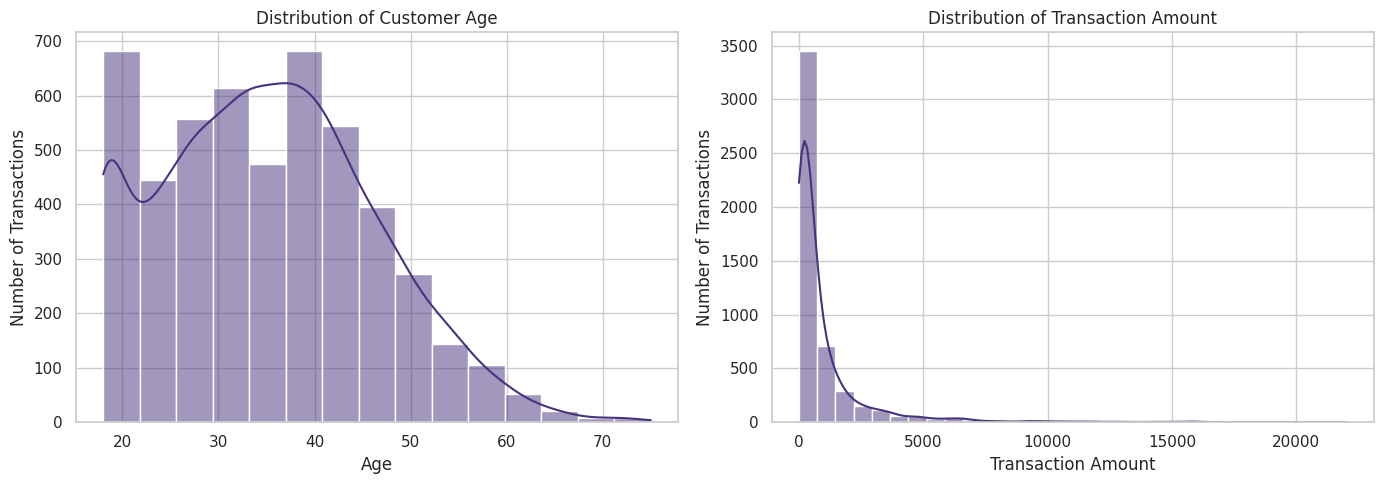

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="Age", bins=15, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Customer Age")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Transactions")
sns.histplot(data=df, x="Total_Amount", bins=30, kde=True,ax=axes[1])
axes[1].set_title("Distribution of Transaction Amount")
axes[1].set_xlabel("Transaction Amount")
axes[1].set_ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

Monthly Sales:


,Total_Sales
Date,
2023-01-31,286694.32
2023-02-28,338784.92
2023-03-31,321716.01
2023-04-30,257332.58
2023-05-31,351902.03
2023-06-30,324356.96
2023-07-31,346618.03
2023-08-31,391505.89
2023-09-30,262602.86


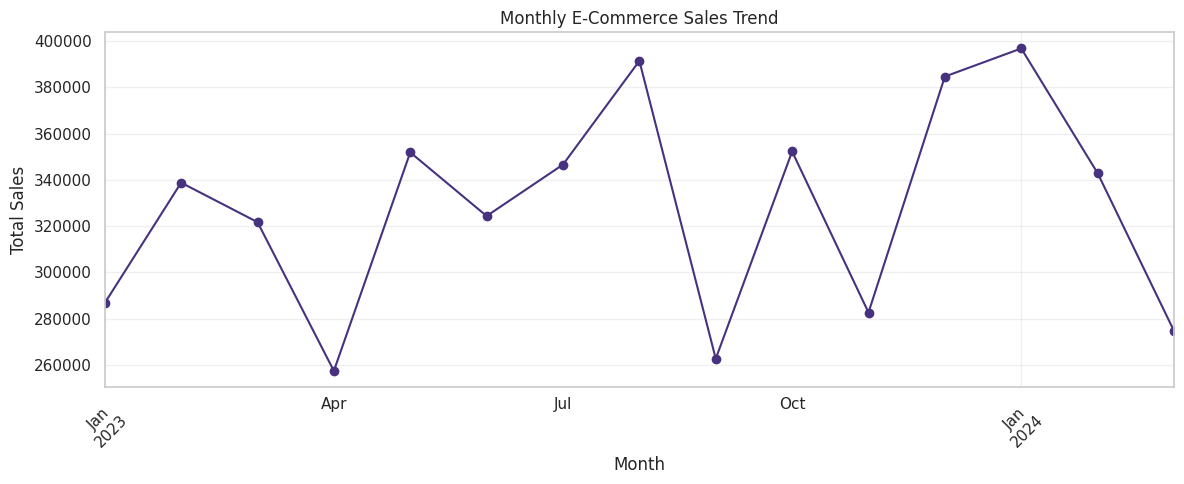

Highest sales month: January 2024
Highest monthly sales: 396,874.92

Lowest sales month: April 2023
Lowest monthly sales: 257,332.58
Average monthly sales: 327,702.97
Number of monthly periods: 15


In [34]:

monthly_sales = (
    df.set_index("Date")["Total_Amount"]
    .resample("ME")
    .sum())
print("Monthly Sales:")
display(monthly_sales.to_frame("Total_Sales"))
plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly E-Commerce Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Highest sales month:",monthly_sales.idxmax().strftime("%B %Y"))
print(f"Highest monthly sales: {monthly_sales.max():,.2f}")
print("\nLowest sales month:",monthly_sales.idxmin().strftime("%B %Y"))
print(f"Lowest monthly sales: {monthly_sales.min():,.2f}")
print(f"Average monthly sales: {monthly_sales.mean():,.2f}")
print("Number of monthly periods:", len(monthly_sales))


In [35]:
print("Total transactions:", len(df))
print("Unique customers:", df["Customer_ID"].nunique())
print("Unique order IDs:", df["Order_ID"].nunique())
customer_frequency = (df.groupby("Customer_ID")["Order_ID"].nunique())
print("\nCustomers with more than one recorded order:",
      (customer_frequency > 1).sum())
print("\nRecorded purchase frequency:")
print(customer_frequency.value_counts().sort_index())
print("\nReturning-customer flag counts:")
print(df["Is_Returning_Customer"].value_counts())

Total transactions: 5000
Unique customers: 5000
Unique order IDs: 5000

Customers with more than one recorded order: 0

Recorded purchase frequency:
Order_ID
1    5000
Name: count, dtype: int64

Returning-customer flag counts:
Is_Returning_Customer
True     2990
False    2010
Name: count, dtype: int64


In [36]:
snapshot_date = df["Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer_ID").agg(Recency=("Date",lambda dates: (snapshot_date - dates.max()).days),Frequency=("Order_ID", "nunique"),Monetary=("Total_Amount", "sum"))
print("RFM dataset shape:", rfm.shape)
display(rfm.head(10))

RFM dataset shape: (5000, 3)


,Recency,Frequency,Monetary
Customer_ID,,,
CUST_00001,124,1,219.32
CUST_00002,394,1,332.34
CUST_00003,439,1,66.44
CUST_00004,72,1,112.65
CUST_00005,311,1,349.45
CUST_00006,326,1,131.96
CUST_00007,337,1,150.41
CUST_00008,380,1,49.10
CUST_00009,74,1,55.89


In [37]:
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"),q=4,labels=[4, 3, 2, 1]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"),q=4,labels=[1, 2, 3, 4]).astype(int)
rfm["RM_Score"] = rfm["R_Score"] + rfm["M_Score"]
print("Recency-Monetary scoring completed!")
print("\nRecency score distribution:")
print(rfm["R_Score"].value_counts().sort_index())
print("\nMonetary score distribution:")
print(rfm["M_Score"].value_counts().sort_index())
display(rfm.head(10))

Recency-Monetary scoring completed!

Recency score distribution:
R_Score
1    1250
2    1250
3    1250
4    1250
Name: count, dtype: int64

Monetary score distribution:
M_Score
1    1250
2    1250
3    1250
4    1250
Name: count, dtype: int64


,Recency,Frequency,Monetary,R_Score,M_Score,RM_Score
Customer_ID,,,,,,
CUST_00001,124,1,219.32,3,2,5
CUST_00002,394,1,332.34,1,2,3
CUST_00003,439,1,66.44,1,1,2
CUST_00004,72,1,112.65,4,1,5
CUST_00005,311,1,349.45,2,3,5
CUST_00006,326,1,131.96,2,2,4
CUST_00007,337,1,150.41,1,2,3
CUST_00008,380,1,49.10,1,1,2
CUST_00009,74,1,55.89,4,1,5


In [39]:
def assign_rm_segment(row):
    if row["R_Score"] >= 3 and row["M_Score"] >= 3:
        return "High Value"
    elif row["R_Score"] >= 3 and row["M_Score"] <= 2:
        return "Loyalty Potential"
    elif row["R_Score"] <= 2 and row["M_Score"] >= 3:
        return "Needs Attention"
    else:
        return "Low Engagement"
rfm["Customer_Segment"] = rfm.apply(assign_rm_segment, axis=1)
segment_counts = rfm["Customer_Segment"].value_counts()
segment_summary = pd.DataFrame({
    "Customers": segment_counts,
    "Percentage": (segment_counts / len(rfm) * 100).round(2)})
print("Recency-Monetary Segmentation:")
display(segment_summary)
display(
    rfm[
        [
            "Recency", "Frequency", "Monetary",
            "R_Score", "M_Score", "RM_Score",
            "Customer_Segment"
        ]
    ].head(10))

Recency-Monetary Segmentation:


,Customers,Percentage
Customer_Segment,,
Loyalty Potential,1253,25.06
Needs Attention,1253,25.06
Low Engagement,1247,24.94
High Value,1247,24.94


,Recency,Frequency,Monetary,R_Score,M_Score,RM_Score,Customer_Segment
Customer_ID,,,,,,,
CUST_00001,124,1,219.32,3,2,5,Loyalty Potential
CUST_00002,394,1,332.34,1,2,3,Low Engagement
CUST_00003,439,1,66.44,1,1,2,Low Engagement
CUST_00004,72,1,112.65,4,1,5,Loyalty Potential
CUST_00005,311,1,349.45,2,3,5,Needs Attention
CUST_00006,326,1,131.96,2,2,4,Low Engagement
CUST_00007,337,1,150.41,1,2,3,Low Engagement
CUST_00008,380,1,49.10,1,1,2,Low Engagement
CUST_00009,74,1,55.89,4,1,5,Loyalty Potential


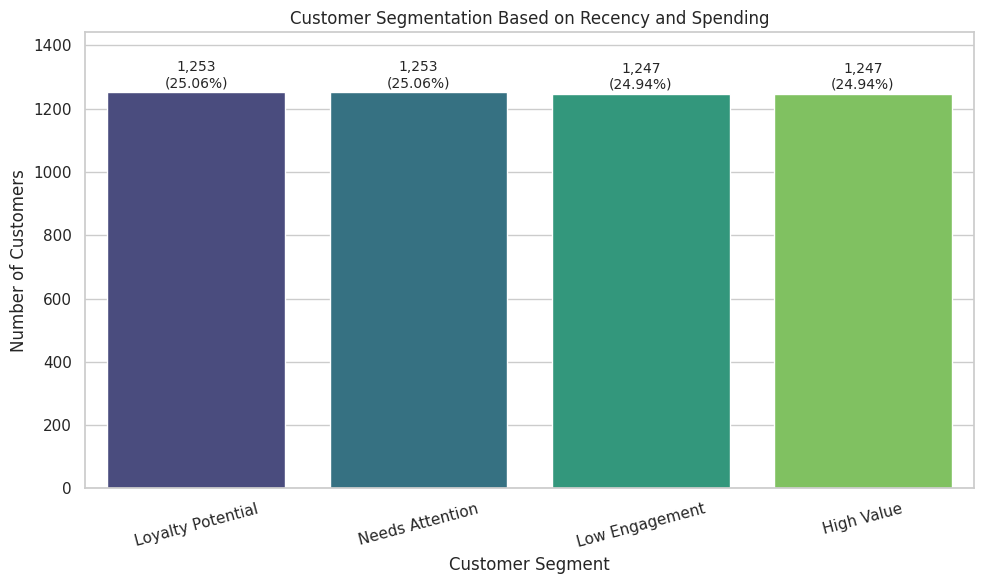

In [40]:
segment_counts = rfm["Customer_Segment"].value_counts()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values,
    hue=segment_counts.index,
    palette="viridis",
    legend=False,
    ax=ax)
total_customers = segment_counts.sum()
for i, count in enumerate(segment_counts.values):
    percentage = count / total_customers * 100
    ax.text(
        i, count + 15,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        fontsize=10)
ax.set_title("Customer Segmentation Based on Recency and Spending")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Number of Customers")
ax.tick_params(axis="x", rotation=15)
ax.set_ylim(0, segment_counts.max() * 1.15)
plt.tight_layout()
plt.show()

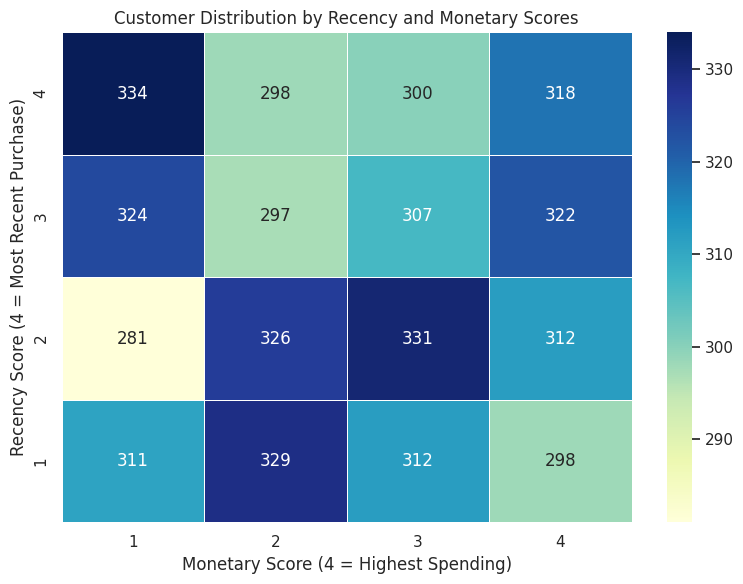

In [41]:

segment_matrix = pd.crosstab(
    rfm["R_Score"],
    rfm["M_Score"]).reindex(index=[4, 3, 2, 1], columns=[1, 2, 3, 4])
plt.figure(figsize=(8, 6))
sns.heatmap(
    segment_matrix,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5)
plt.title("Customer Distribution by Recency and Monetary Scores")
plt.xlabel("Monetary Score (4 = Highest Spending)")
plt.ylabel("Recency Score (4 = Most Recent Purchase)")
plt.tight_layout()
plt.show()

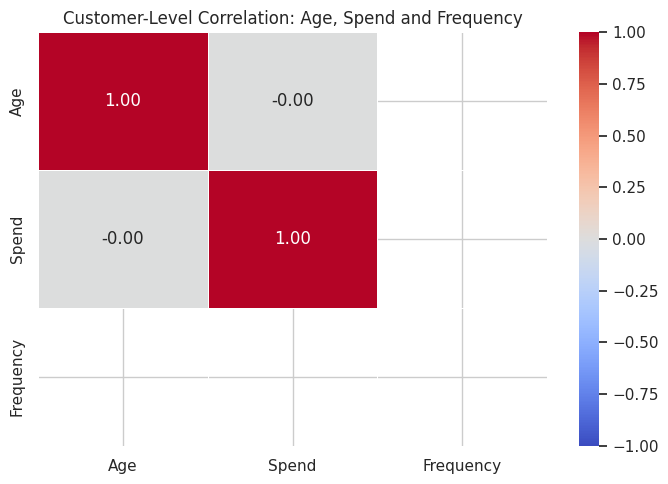

Unique frequency values: [1]


In [42]:

customer_analysis = df.groupby("Customer_ID").agg(
    Age=("Age", "first"),
    Spend=("Total_Amount", "sum"),
    Frequency=("Order_ID", "nunique"))
correlation = customer_analysis[
    ["Age", "Spend", "Frequency"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1)
plt.title("Customer-Level Correlation: Age, Spend and Frequency")
plt.tight_layout()
plt.show()
print("Unique frequency values:",
      customer_analysis["Frequency"].unique())

Total customers: 5000
Total revenue: 4,915,544.57
Top 20% customer count: 1000
Revenue from top 20%: 72.04%


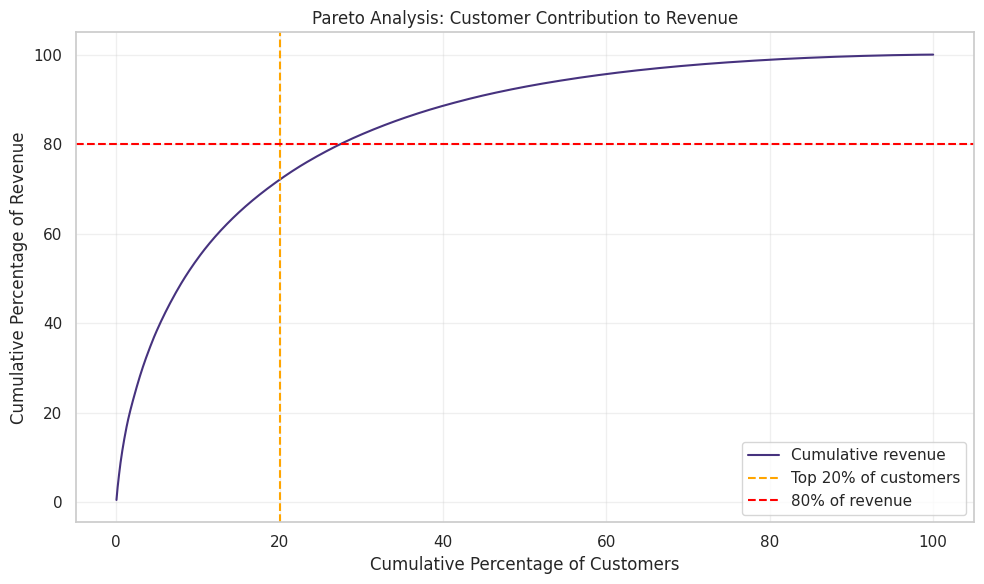

In [44]:
customer_spending = (
    rfm["Monetary"]
    .sort_values(ascending=False)
    .reset_index())
total_revenue = customer_spending["Monetary"].sum()
customer_spending["Cumulative_Revenue"] = (
    customer_spending["Monetary"].cumsum()
    / total_revenue * 100)
customer_spending["Cumulative_Customers"] = (
    (customer_spending.index + 1)
    / len(customer_spending) * 100)
top_20_count = int(len(customer_spending) * 0.20)

top_20_revenue = (
    customer_spending.head(top_20_count)["Monetary"].sum()
    / total_revenue * 100)
print("Total customers:", len(customer_spending))
print(f"Total revenue: {total_revenue:,.2f}")
print("Top 20% customer count:", top_20_count)
print(f"Revenue from top 20%: {top_20_revenue:.2f}%")
plt.figure(figsize=(10, 6))
plt.plot(
    customer_spending["Cumulative_Customers"],
    customer_spending["Cumulative_Revenue"],
    label="Cumulative revenue")
plt.axvline(
    20, linestyle="--", color="orange",
    label="Top 20% of customers")
plt.axhline(
    80, linestyle="--", color="red",
    label="80% of revenue")
plt.title("Pareto Analysis: Customer Contribution to Revenue")
plt.xlabel("Cumulative Percentage of Customers")
plt.ylabel("Cumulative Percentage of Revenue")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Sales by Product Category:


,Total_Sales
Product_Category,
Electronics,2328806.81
Home & Garden,908348.86
Sports,754563.56
Fashion,375214.93
Toys,223142.48
Beauty,156584.74
Food,96138.67
Books,72744.52


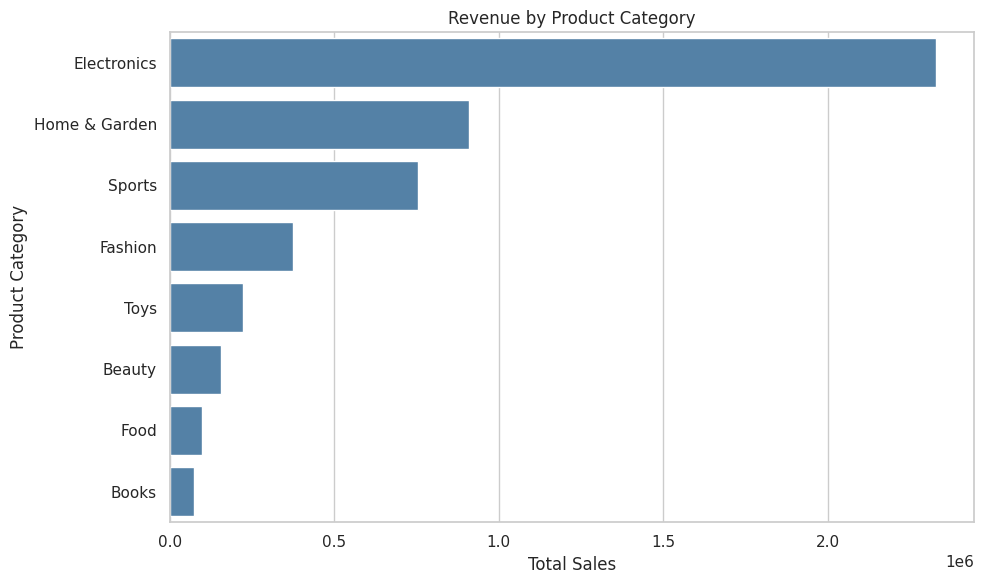

Highest-revenue category: Electronics


In [46]:

category_sales = (
    df.groupby("Product_Category")["Total_Amount"]
    .sum()
    .sort_values(ascending=False))
print("Sales by Product Category:")
display(category_sales.to_frame("Total_Sales"))
plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_sales.values,
    y=category_sales.index,
    color="steelblue")
plt.title("Revenue by Product Category")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()
print("Highest-revenue category:", category_sales.idxmax())

Payment Method Usage:


,Number_of_Orders
Payment_Method,
Credit Card,2012
Debit Card,1265
Digital Wallet,965
Bank Transfer,510
Cash on Delivery,248


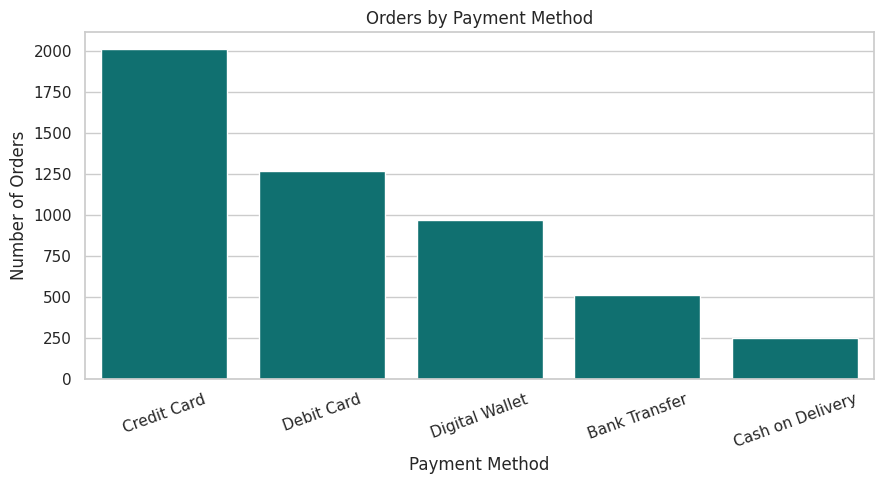

Most commonly used payment method: Credit Card


In [47]:
payment_counts = df["Payment_Method"].value_counts()
print("Payment Method Usage:")
display(payment_counts.to_frame("Number_of_Orders"))
plt.figure(figsize=(9, 5))
sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values,
    color="teal")
plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print("Most commonly used payment method:",
      payment_counts.idxmax())

In [48]:
print("Total customers:", len(rfm))
print("Unique customers:", rfm.index.nunique())
print("Missing segment labels:",rfm["Customer_Segment"].isna().sum())
print("Missing Recency scores:", rfm["R_Score"].isna().sum())
print("Missing Monetary scores:", rfm["M_Score"].isna().sum())
print("Frequency values:", sorted(rfm["Frequency"].unique()))
assert len(rfm) == 5000
assert rfm.index.nunique() == 5000
assert rfm["Customer_Segment"].notna().all()
assert rfm["R_Score"].between(1, 4).all()
assert rfm["M_Score"].between(1, 4).all()
assert rfm["Frequency"].eq(1).all()
print("\nAll validation checks passed!")

Total customers: 5000
Unique customers: 5000
Missing segment labels: 0
Missing Recency scores: 0
Missing Monetary scores: 0
Frequency values: [np.int64(1)]

All validation checks passed!


# Conclusion

The E-Commerce Customer Behavior Analysis project examined sales trends, product performance, customer spending, and purchasing patterns using Python, Pandas, Matplotlib, and Seaborn. The dataset contained 5,000 transactions with total revenue of 4,915,544.57.

Electronics generated the highest revenue, while January 2024 recorded the highest monthly sales at 396,874.92. Credit cards were the most commonly used payment method. The top 20% of customers contributed 72.04% of total revenue, indicating that higher-spending customers accounted for a substantial share of sales.

Recency–Monetary segmentation classified customers into High Value, Loyalty Potential, Needs Attention, and Low Engagement groups. However, each customer has only one recorded order, so purchase frequency cannot distinguish customers in this dataset. These segments are provisional and should not be interpreted as confirmed loyalty or churn classifications.

Overall, this project demonstrates how exploratory data analysis and visualization can identify sales trends, highlight revenue opportunities, and support data-driven business decisions. A dataset containing multiple orders per customer would enable more reliable full RFM segmentation and customer-retention analysis.